# Basics

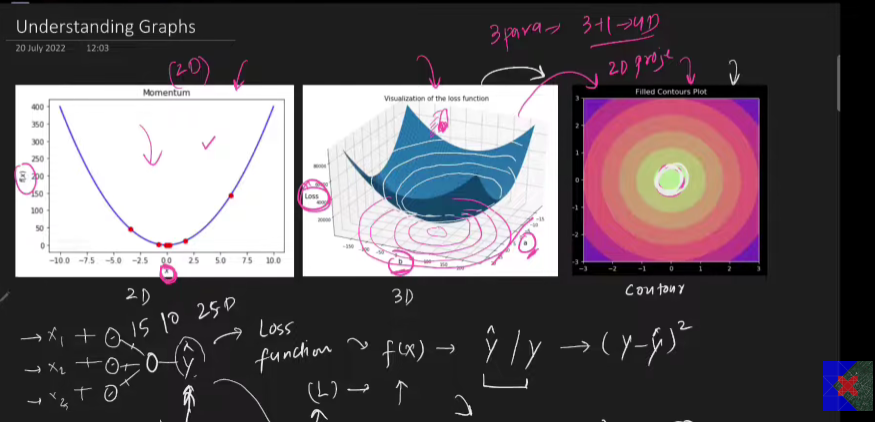

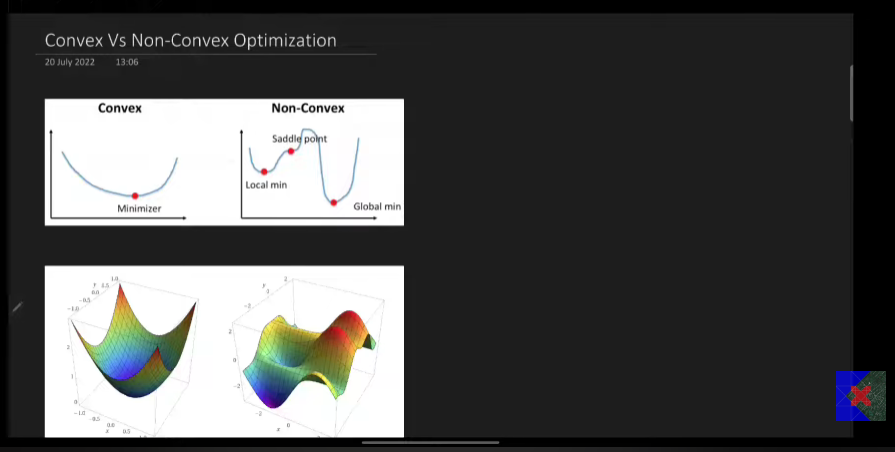

- In NN non-convex objective fuction are very common

# Problems with non-convex optimization

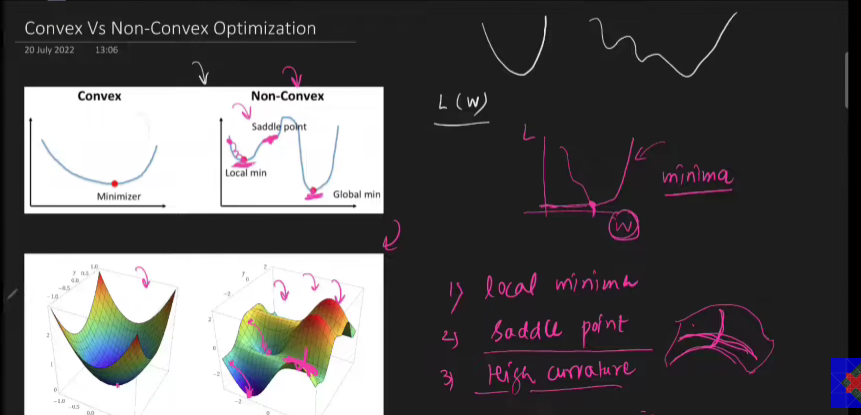
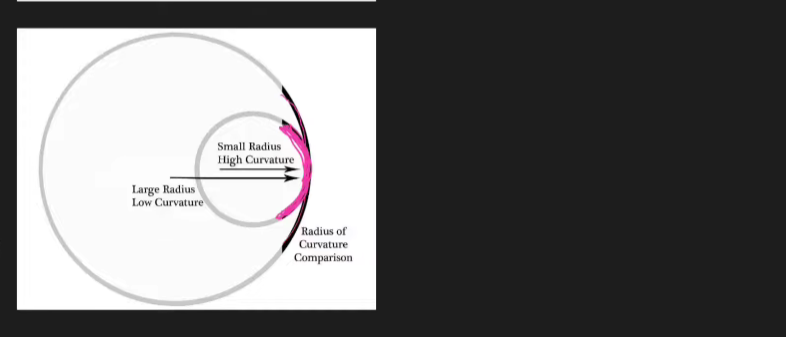

1. **Local Minima**: In non-convex optimization, the objective function may have multiple local minima. Gradient descent can get stuck in these local minima, preventing it from finding the global minimum.
2. **Saddle Points**: Non-convex functions can have saddle points, where the gradient is zero but the point is not a minimum. Gradient descent can converge to these saddle points
3. **High Curvature Regions**: Non-convex functions can have regions with high curvature, because of which the gradient will be very small and the optimization will be very slow. This can lead to slow convergence

- So momentum is used to overcome these problems. It helps to accelerate the optimization in the relevant direction and dampens oscillations. It does this by adding a fraction of the previous update to the current update.

- The single most important thing of using momentum based optimzation is the speed, it is faster than the vanilla gradient descent.


## The core idea of momentum optimization:

- If our previous gradients are pointing in the same direction as the current gradient, then we will increase speed in that direction.

- If our previous gradients are pointing in the opposite direction as the current gradient, then we will decrease speed in that direction.

- Let's see how we can implement this mathematically.

## Mathematical Implementation of momentum optimization:

### Normal gradient descent

$$
W_{t+1} = W_t - \eta \, \nabla L(W_t)
$$

Here $W_t$ is the weight at step $t$, $\eta$ is the learning rate, and $\nabla L(W_t)$ is the gradient of the loss. Each step depends **only on the current gradient**.

### Momentum

In momentum optimization, we introduce a new variable $v_t$, called the **velocity**. It remembers the direction we have been moving in.

**Velocity update:**

$$
v_t = \beta \, v_{t-1} + \eta \, \nabla L(W_t)
$$

**Weight update:**

$$
W_{t+1} = W_t - v_t
$$

**Terms used:**

- $v_t$ is the **velocity at time step $t$**.
- $\beta$ is the **momentum hyperparameter** (also called the **decay value**), usually 0.9. It controls **how much of the previous velocity is retained**.
- $\eta$ is the **learning rate**.

<mark>The velocity is an **exponentially weighted sum of past gradients**, similar to an EWMA.</mark>

### The two terms of $v_t$

$v_t$ has 2 terms:

- **$\beta \, v_{t-1}$** is the contribution of the **previous velocity** (the history of past gradients) to the current velocity.
- **$\eta \, \nabla L(W_t)$** is the contribution of the **current gradient** to the current velocity.

Expanding it shows how the history builds up:

$$
v_t = \eta \nabla L_t + \beta \, \eta \nabla L_{t-1} + \beta^2 \, \eta \nabla L_{t-2} + \dots
$$

**Recent gradients get more weight, and older gradients fade away by a factor of $\beta$ at each step.**

## Why the weights converge faster

- <mark>If the gradients keep pointing in the **same direction**, they **add up** and the velocity grows, so we take **bigger steps** towards the minimum.</mark>
- <mark>If the gradients keep **flipping direction** (oscillating), they **cancel each other out**, so the movement in that direction is **reduced**.</mark>
- Think of a **heavy ball rolling downhill**. It gains speed on a steady slope and is not thrown around by every small bump.


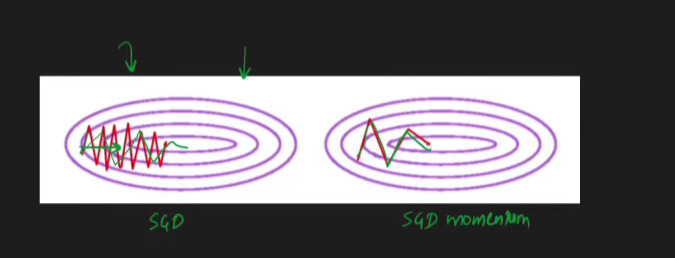

- You can see velocity in the horizontal direction increases because of the momentum term pointing in the same direction as the current gradient. 

- It is also decreasing the velocity in the vertical direction because of the momentum term pointing in the opposite direction as the current gradient.

## Effect of $\beta$ in Momentum

Momentum update rule:

$$
v_t = \beta \, v_{t-1} + \eta \, \nabla L(\theta_{t-1})
\qquad
\theta_t = \theta_{t-1} - v_t
$$

Here $v_t$ is the **velocity** (running accumulation of past gradients), $\beta$ is the **momentum coefficient** ($0 \le \beta < 1$), and $\eta$ is the learning rate.

- The value of $\beta$ controls **how much of the previous velocity is retained**.

- A **high** $\beta$ (e.g., 0.9) means the algorithm **retains more of the previous velocity**, which gives **smoother updates**. Noisy gradient directions cancel out, and movement along a consistent direction builds up speed.

- A **low** $\beta$ (e.g., 0.3) means the algorithm **retains less of the previous velocity**, so the update depends more on the **current gradient**. There is **less smoothing**, so the path is **noisier** and behaves more like plain gradient descent.

- For $\beta = 0$, it is **equivalent to vanilla gradient descent**, because the previous velocity is not retained at all ($v_t = \eta \nabla L$).

- As $\beta \to 1$, there is **almost no decay** of the previous velocites. The velocity keeps accumulating and old gradients are never forgotten, like a ball rolling with **no friction**. This is not good, because it leads to **overshooting** the minimum and **oscillating** around it for a long time without settling. That is why $\beta$ is kept **strictly below 1** (commonly 0.9).

See this part of the video: [link](https://www.youtube.com/watch?v=vVS4csXRlcQ&list=PLKnIA16_RmvYuZauWaPlRTC54KxSNLtNn&index=34) (32:00), it shows visualation of momentum

# Problems with Momentum

- Though it will converge faster than vanilla gradient descent, but after reaching the minimum, it will oscillate around the minimum just like a ball rolling in a bowl before it finally settles down. This is because the momentum term keeps adding to the velocity even after reaching the minimum. So it will overshoot the minimum and oscillate around it.

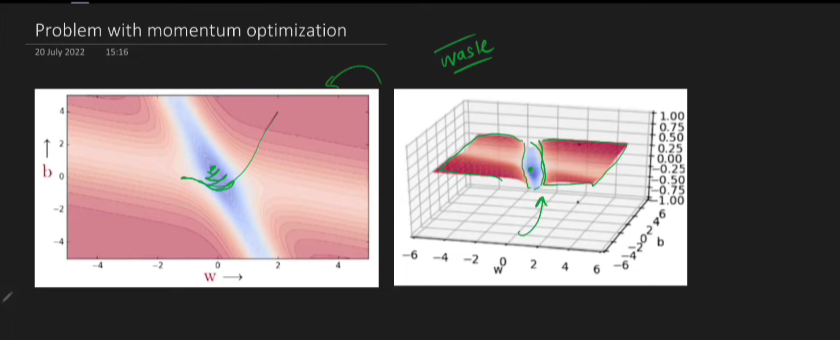

- The oscillation around the minimum is the biggest flaw with momentum, and thats why it can't become the fastest optimization algorithm. It will converge faster than vanilla gradient descent, but it will oscillate around the minimum and take a long time to settle down.